<a href="https://colab.research.google.com/github/pendulumswings/pendulumswings.github.io/blob/main/scripts/chapter5/pendulum_bug_work.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Verification of the Work-Energy Theorem Across All Behavioral Regimes (small angle, oscillation, rotation). Slow bug motion.

Simulating: 1. Small Angle Oscillation | Ping-Pong mode...
Simulating: 1. Small Angle Oscillation | Harmonic mode...
Simulating: 2. Large Angle Oscillation | Ping-Pong mode...
Simulating: 2. Large Angle Oscillation | Harmonic mode...
Simulating: 3. Rot -> Osc (Separatrix Crossing) | Ping-Pong mode...
Simulating: 3. Rot -> Osc (Separatrix Crossing) | Harmonic mode...
Simulating: 4. Fast Rot Marginal (Separatrix Crossing) | Ping-Pong mode...
Simulating: 4. Fast Rot Marginal (Separatrix Crossing) | Harmonic mode...
Simulating: 5. Continuous Rotation | Ping-Pong mode...
Simulating: 5. Continuous Rotation | Harmonic mode...


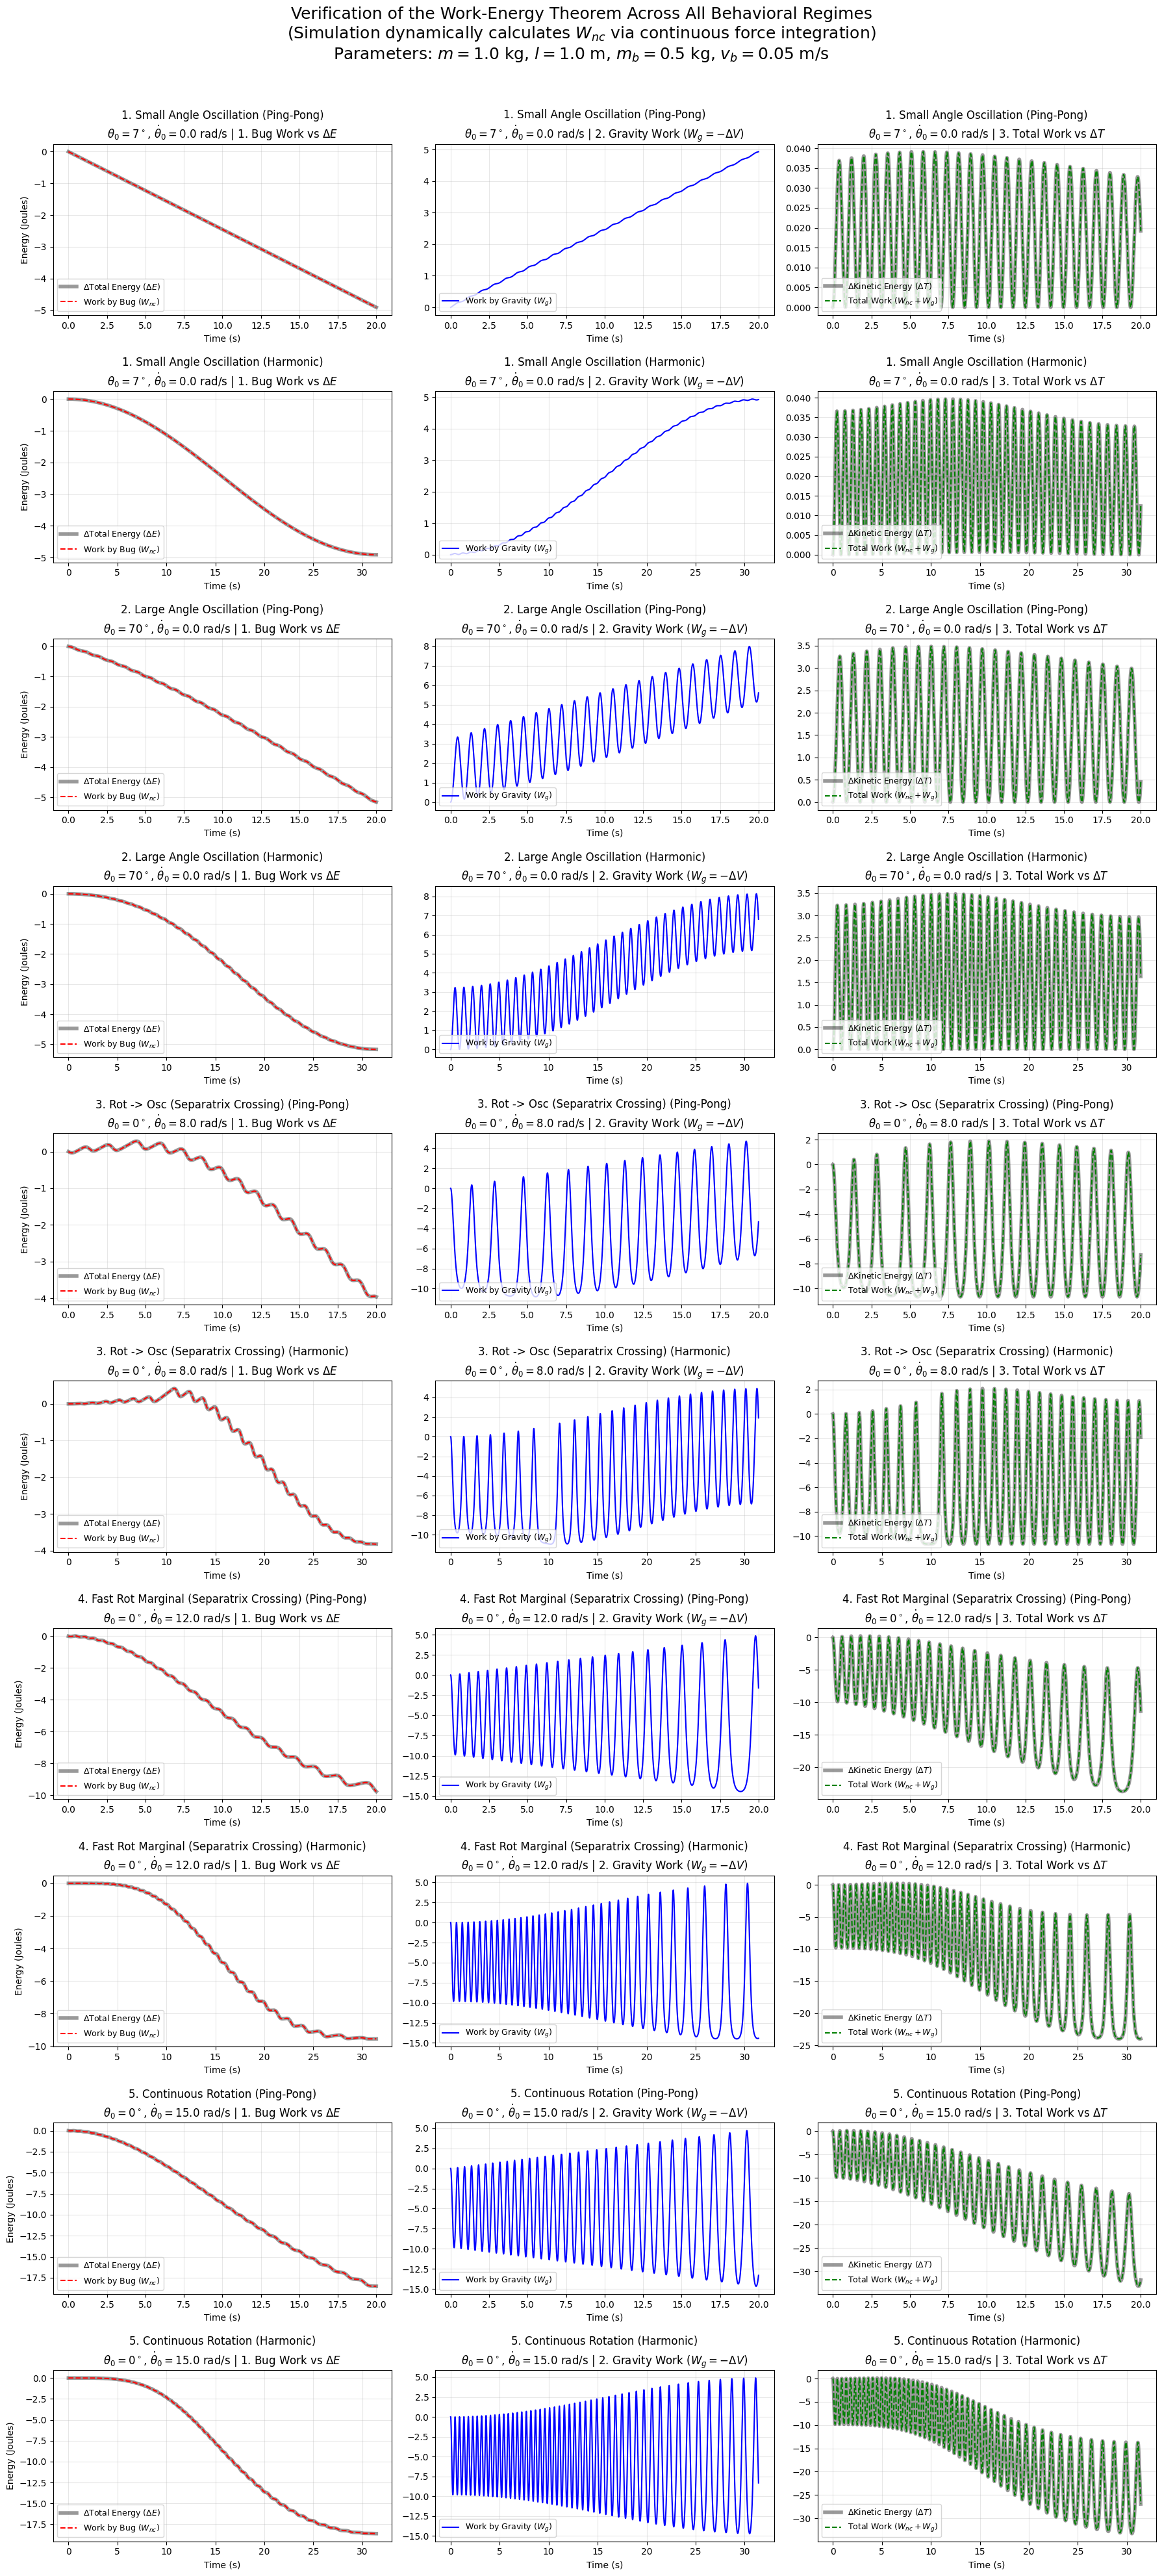

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def get_kinematics(t, v_b, p, mode):
    """Calculates r, r_dot, and r_ddot for one outward sweep."""
    l = p['l']
    if mode == 'pingpong':
        r = v_b * t
        r_dot = v_b
        r_ddot = 0.0
        return r, r_dot, r_ddot
    elif mode == 'harmonic':
        omega_b = 2 * v_b / l
        r = (l / 2) * (1 - np.cos(omega_b * t))
        r_dot = (l / 2) * omega_b * np.sin(omega_b * t)
        r_ddot = (l / 2) * omega_b**2 * np.cos(omega_b * t)
        return r, r_dot, r_ddot

def dy_dt(t, y, v_b, p, mode):
    """
    Differential equations for the system.
    y = [theta, omega, W_nc]
    We integrate the non-conservative work done by the bug alongside the dynamics!
    """
    theta, omega, W_nc = y
    r, r_dot, r_ddot = get_kinematics(t, v_b, p, mode)

    # Inertia and Effective Mass Lever
    I = (1/3) * p['m'] * p['l']**2 + p['m_b'] * r**2
    M_eff = 0.5 * p['m'] * p['l'] + p['m_b'] * r

    # Angular Acceleration
    alpha = (- 2 * p['m_b'] * r * r_dot * omega - M_eff * p['g'] * np.sin(theta)) / I

    # Rate of Non-Conservative Work done by Bug (dW_nc / dt)
    # F_bug = m_b * r_ddot - F_centrifugal - F_gravity_radial
    F_bug = p['m_b'] * r_ddot - p['m_b'] * r * omega**2 - p['m_b'] * p['g'] * np.cos(theta)
    dW_nc_dt = F_bug * r_dot

    return np.array([omega, alpha, dW_nc_dt])

def solve_rk4(y0, v_b, p, mode, t_span, dt=0.005):
    """Standard 4th Order Runge-Kutta Integrator."""
    t_vals = np.arange(t_span[0], t_span[1] + dt, dt)
    y_vals = np.zeros((len(t_vals), 3))
    y_vals[0] = y0

    for i in range(1, len(t_vals)):
        t = t_vals[i-1]
        y = y_vals[i-1]

        k1 = dy_dt(t, y, v_b, p, mode)
        k2 = dy_dt(t + 0.5*dt, y + 0.5*dt*k1, v_b, p, mode)
        k3 = dy_dt(t + 0.5*dt, y + 0.5*dt*k2, v_b, p, mode)
        k4 = dy_dt(t + dt, y + dt*k3, v_b, p, mode)

        y_vals[i] = y + (dt/6.0) * (k1 + 2*k2 + 2*k3 + k4)

    return t_vals, y_vals

def simulate_and_calculate(v_b, p, mode, y0_case):
    # Determine the transit time for one sweep (from pivot to end of rod)
    if mode == 'pingpong':
        T_sweep = p['l'] / v_b
    else:
        omega_b = 2 * v_b / p['l']
        T_sweep = np.pi / omega_b

    # Initial conditions: theta=y0_case[0], omega=y0_case[1], initial Bug Work=0
    y0 = [y0_case[0], y0_case[1], 0.0]

    # Initial Kinematics to calculate base energy
    r0, r_dot0, _ = get_kinematics(0, v_b, p, mode)
    I0 = (1/3) * p['m'] * p['l']**2 + p['m_b'] * r0**2
    M_eff0 = 0.5 * p['m'] * p['l'] + p['m_b'] * r0

    T_initial = 0.5 * I0 * y0[1]**2 + 0.5 * p['m_b'] * r_dot0**2
    V_initial = - M_eff0 * p['g'] * np.cos(y0[0])
    E_initial = T_initial + V_initial

    # Simulate
    t_vals, y_vals = solve_rk4(y0, v_b, p, mode, [0, T_sweep])

    # Data containers
    Delta_E, Delta_T, W_gravity, W_bug = [], [], [], y_vals[:, 2]

    for i in range(len(t_vals)):
        theta, omega, _ = y_vals[i]
        r, r_dot, _ = get_kinematics(t_vals[i], v_b, p, mode)

        I = (1/3) * p['m'] * p['l']**2 + p['m_b'] * r**2
        M_eff = 0.5 * p['m'] * p['l'] + p['m_b'] * r

        # Instantaneous Energies
        T_current = 0.5 * I * omega**2 + 0.5 * p['m_b'] * r_dot**2
        V_current = - M_eff * p['g'] * np.cos(theta)
        E_current = T_current + V_current

        # Calculate Changes and Gravity Work
        Delta_E.append(E_current - E_initial)
        Delta_T.append(T_current - T_initial)
        W_gravity.append(-(V_current - V_initial)) # W_g = -Delta V

    return t_vals, np.array(W_bug), np.array(W_gravity), np.array(Delta_E), np.array(Delta_T)

def main():
    # Sync parameters with the adiabatic simulation script
    p = {'m': 1.0, 'l': 1.0, 'm_b': 0.5, 'g': 9.81}
    v_b = 0.05

    cases = [
        {"name": "1. Small Angle Oscillation", "y0": [7 * np.pi / 180, 0.0]},
        {"name": "2. Large Angle Oscillation", "y0": [70 * np.pi / 180, 0.0]},
        {"name": "3. Rot -> Osc (Separatrix Crossing)", "y0": [0.0, 8.0]},
        {"name": "4. Fast Rot Marginal (Separatrix Crossing)", "y0": [0.0, 12.0]},
        {"name": "5. Continuous Rotation", "y0": [0.0, 15.0]}
    ]

    modes = ['pingpong', 'harmonic']
    mode_titles = {'pingpong': 'Ping-Pong', 'harmonic': 'Harmonic'}

    # Create a massive 10x3 grid for the plots
    fig, axes = plt.subplots(10, 3, figsize=(18, 40))

    row = 0
    for case in cases:
        for mode in modes:
            print(f"Simulating: {case['name']} | {mode_titles[mode]} mode...")
            t, W_bug, W_grav, dE, dT = simulate_and_calculate(v_b, p, mode, case['y0'])

            # Format the initial conditions for the titles
            th0_deg = np.rad2deg(case['y0'][0])
            om0 = case['y0'][1]
            ic_str = f"$\\theta_0={th0_deg:.0f}^\\circ$, $\\dot{{\\theta}}_0={om0:.1f}$ rad/s"

            # Plot 1: Work by Bug vs Change in Total Mechanical Energy
            ax = axes[row, 0]
            ax.plot(t, dE, label=r'$\Delta$Total Energy ($\Delta E$)', color='black', linewidth=4, alpha=0.4)
            ax.plot(t, W_bug, label=r'Work by Bug ($W_{nc}$)', color='red', linestyle='--')
            ax.set_title(f"{case['name']} ({mode_titles[mode]})\n{ic_str} | 1. Bug Work vs $\\Delta E$")
            ax.set_xlabel('Time (s)')
            ax.set_ylabel('Energy (Joules)')
            ax.legend(loc='lower left', fontsize=9)
            ax.grid(True, alpha=0.3)

            # Plot 2: Work by Gravity vs Negative Change in Potential Energy
            ax = axes[row, 1]
            ax.plot(t, W_grav, label=r'Work by Gravity ($W_g$)', color='blue')
            ax.set_title(f"{case['name']} ({mode_titles[mode]})\n{ic_str} | 2. Gravity Work ($W_g = -\\Delta V$)")
            ax.set_xlabel('Time (s)')
            ax.legend(loc='lower left', fontsize=9)
            ax.grid(True, alpha=0.3)

            # Plot 3: Total Work (Bug + Gravity) vs Change in Kinetic Energy
            ax = axes[row, 2]
            Total_Work = W_bug + W_grav
            ax.plot(t, dT, label=r'$\Delta$Kinetic Energy ($\Delta T$)', color='black', linewidth=4, alpha=0.4)
            ax.plot(t, Total_Work, label=r'Total Work ($W_{nc} + W_g$)', color='green', linestyle='--')
            ax.set_title(f"{case['name']} ({mode_titles[mode]})\n{ic_str} | 3. Total Work vs $\\Delta T$")
            ax.set_xlabel('Time (s)')
            ax.legend(loc='lower left', fontsize=9)
            ax.grid(True, alpha=0.3)

            row += 1

    plt.suptitle(f"Verification of the Work-Energy Theorem Across All Behavioral Regimes\n"
                 f"(Simulation dynamically calculates $W_{{nc}}$ via continuous force integration)\n"
                 f"Parameters: $m={p['m']}$ kg, $l={p['l']}$ m, $m_b={p['m_b']}$ kg, $v_b={v_b}$ m/s",
                 fontsize=18, y=0.99)

    plt.tight_layout(rect=[0, 0, 1, 0.98], h_pad=1.5)
    plt.show()

if __name__ == "__main__":
    main()